In [24]:
import pandas as pd
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


# Loading the data

In [25]:
df= pd.read_excel("/kaggle/input/datasets/daminijadhav2003/crop-predication-dataset-based-on-nashik-region/Crop_Predication_dataset.xlsx")
df.head()

,ph,EC,CaCO3,OC,N,P,K,label
0,5.6,0.330,6.0,0.16,125.0,37.0,200.0,bajra
1,7.5,0.820,7.0,0.15,132.0,35.0,169.0,bajra
2,5.6,0.212,3.0,0.19,145.0,38.0,122.0,bajra
3,6.9,0.469,9.0,0.14,124.0,38.0,134.0,bajra
4,7.3,0.649,6.0,0.18,125.0,35.0,162.0,bajra


In [26]:
df.shape

(1239, 8)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1239 entries, 0 to 1238
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ph      1239 non-null   float64
 1   EC      1239 non-null   float64
 2   CaCO3   1239 non-null   float64
 3   OC      1239 non-null   float64
 4   N       1239 non-null   float64
 5   P       1239 non-null   float64
 6   K       1239 non-null   float64
 7   label   1239 non-null   object 
dtypes: float64(7), object(1)
memory usage: 77.6+ KB


In [28]:
df.describe()

,ph,EC,CaCO3,OC,N,P,K
count,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000,1239.000000
mean,8.598764,0.435471,5.873971,1.657602,141.332155,27.511345,203.485446
std,33.566082,0.250498,3.683088,2.003687,67.349392,21.106725,149.758253
min,5.000000,0.007000,0.000000,0.001900,0.000000,1.030000,35.000000
25%,6.126350,0.250000,3.600000,0.195000,83.000000,12.000000,71.000000
50%,6.600000,0.341000,4.700000,0.520000,151.000000,18.000000,170.000000
75%,7.118269,0.610000,7.000000,3.200000,184.730000,39.000000,304.050000
max,598.000000,1.640000,18.000000,8.500000,342.340000,85.000000,1170.350000


In [29]:
df.isnull().sum()

ph       0
EC       0
CaCO3    0
OC       0
N        0
P        0
K        0
label    0
dtype: int64

In [30]:
df.duplicated().sum()

np.int64(80)

In [31]:
df = df.drop_duplicates()
df = df[(df['ph'] >= 0) & (df['ph'] <= 14)]

npk_cols = ['N', 'P', 'K']
for col in npk_cols:
    median_val = df[df[col] > 0][col].median()
    df[col] = df[col].replace(0, median_val)

k_cap = df['K'].quantile(0.99)
p_cap = df['P'].quantile(0.99)
df.loc[df['K'] > k_cap, 'K'] = k_cap
df.loc[df['P'] > p_cap, 'P'] = p_cap

print("Cleaned Data Shape:", df.shape)
print(df['label'].value_counts())

Cleaned Data Shape: (1158, 8)
label
grapes         116
cabbage        101
bajra          101
maize          101
jowar          101
sugarcane      101
wheat          101
pomegranate    100
cotton          84
soybean         82
tomato          55
rice            51
onion           34
potato          24
cauliflower      6
Name: count, dtype: int64


# Univariate Analysis

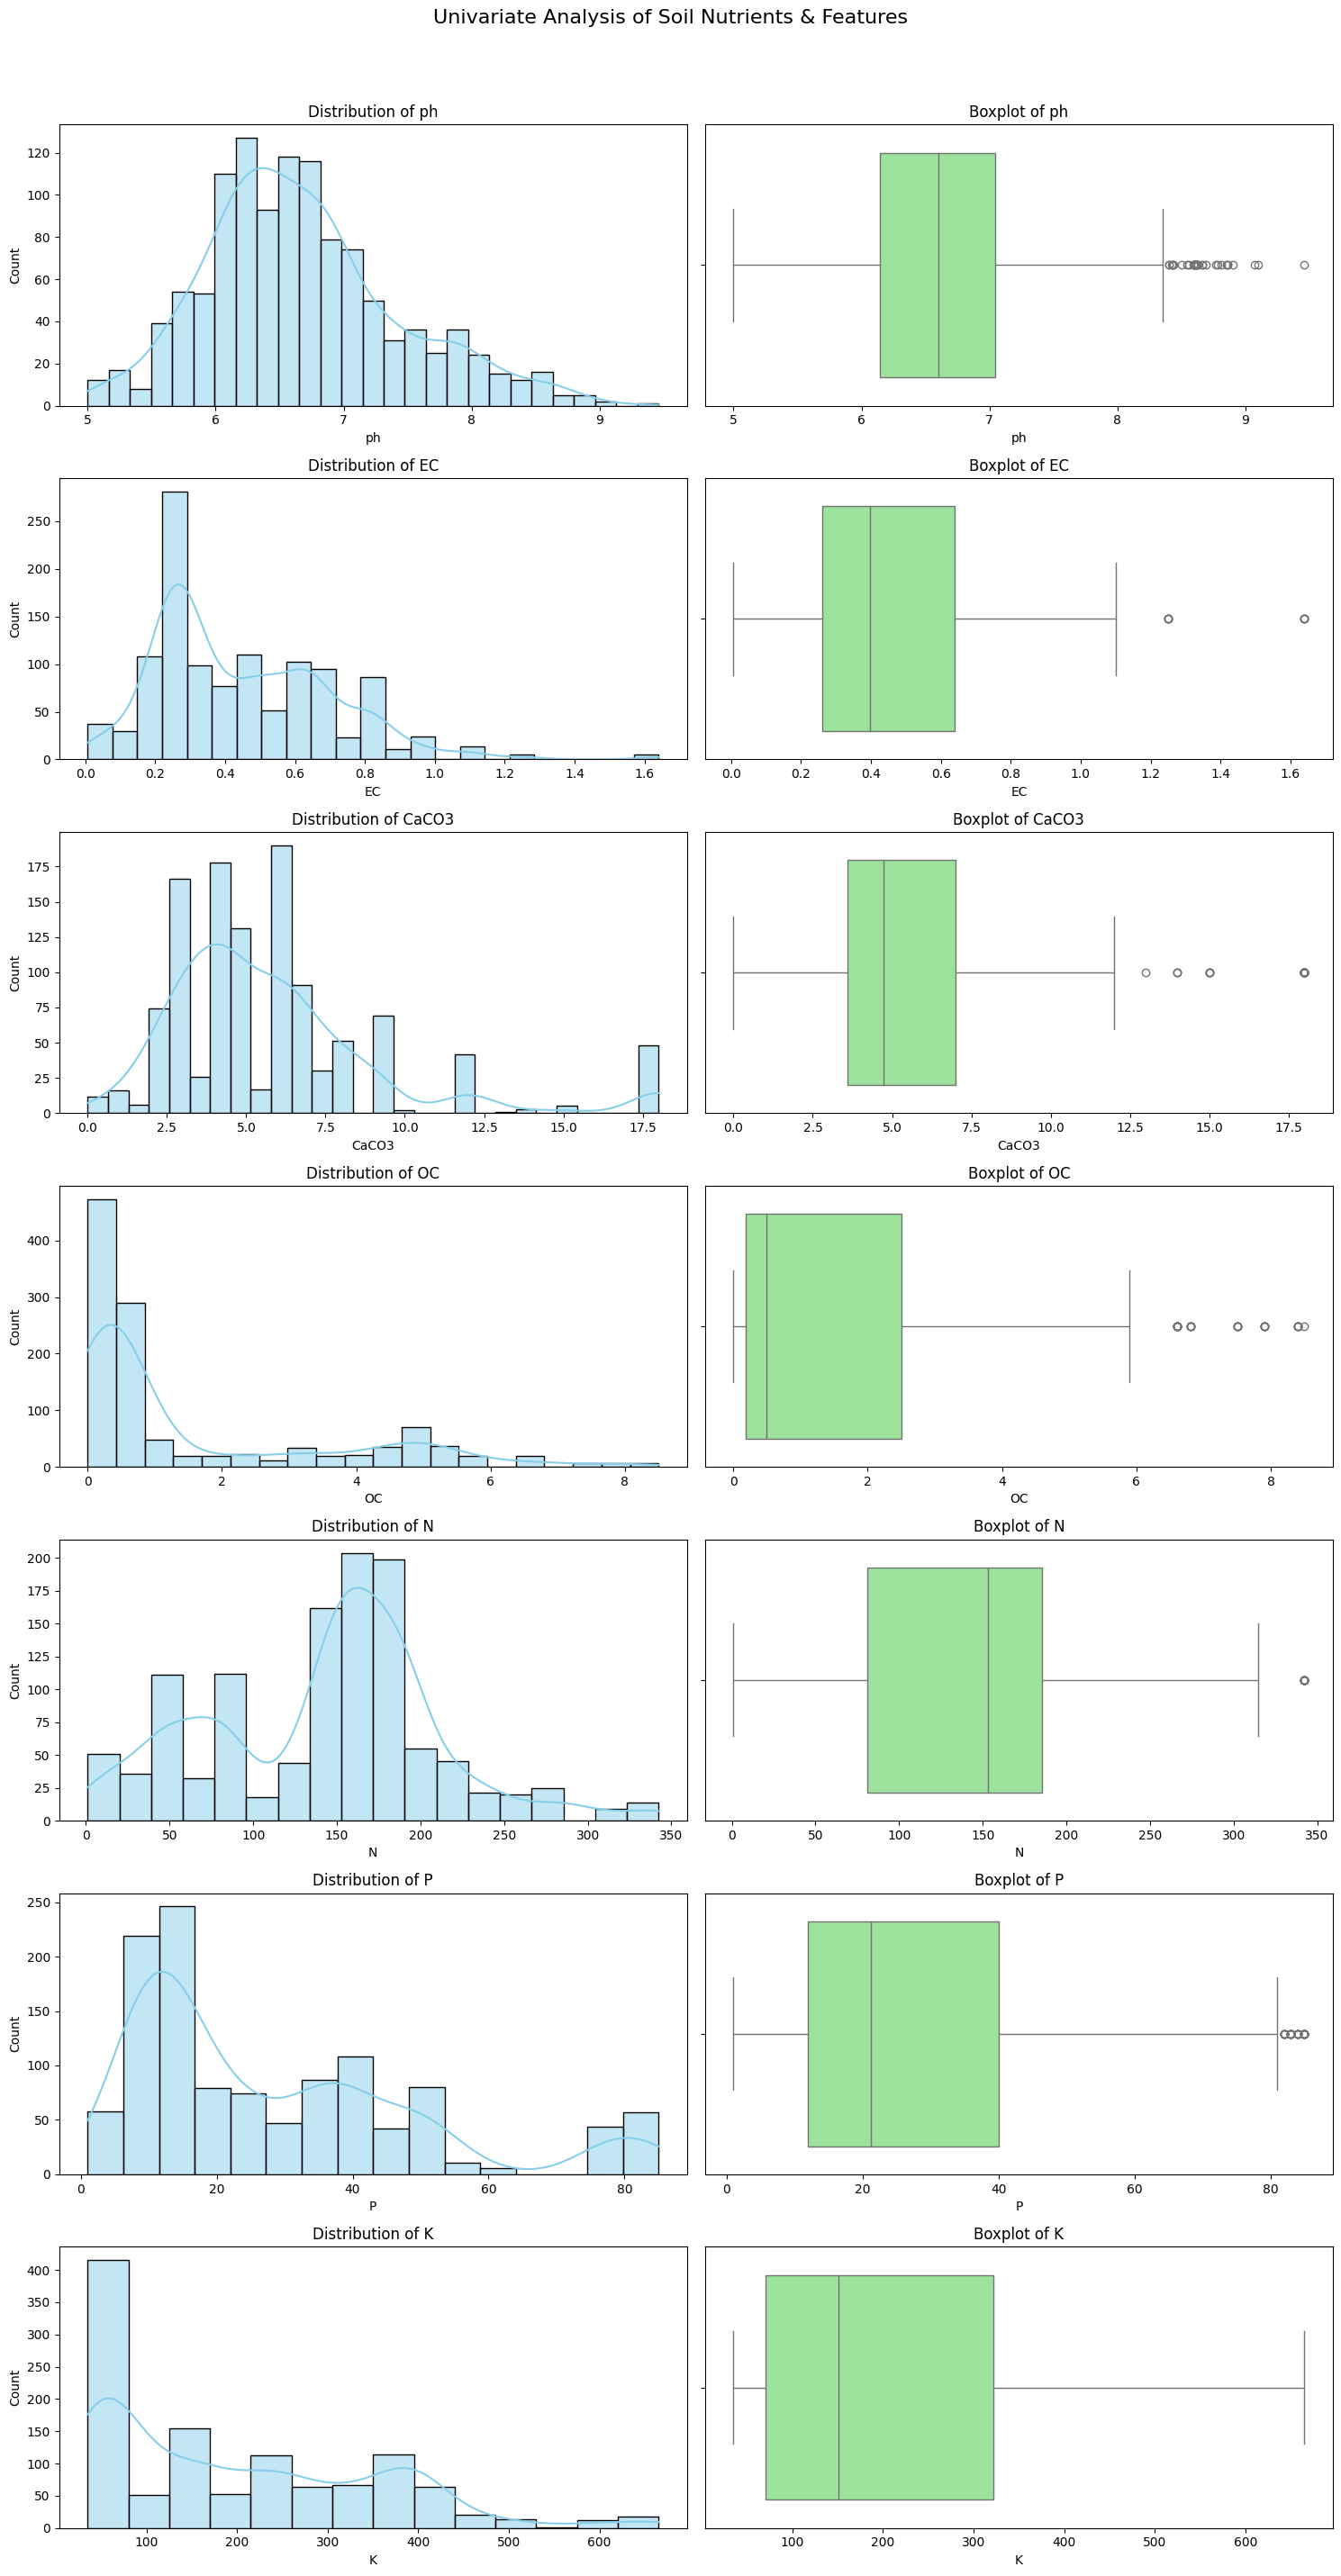

In [32]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()

fig, axes = plt.subplots(nrows=len(num_cols), ncols=2, figsize=(15, 4 * len(num_cols)))
fig.suptitle('Univariate Analysis of Soil Nutrients & Features', fontsize=16, y=1.02)

for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color='skyblue')
    axes[i, 0].set_title(f'Distribution of {col}')
    
    sns.boxplot(x=df[col], ax=axes[i, 1], color='lightgreen')
    axes[i, 1].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

**Univariate analysis ne soil features ki individual distributions aur unke anomalies ko wazeh kiya. Boxplots aur histograms se pata chala ke numerical columns jaise 'ph', 'P', aur 'K' mein extreme outliers mojood hain (maslan pH ki maximum value 598.0 jo scientifically impossible hai). Iske ilawa, 'K' (Potassium) aur 'P' (Phosphorus) ki standard deviation kafi high hai, jo mitti ki quality mein heavy variance ko zahir karti hai. Is insight ne humein technically yeh bataya ke model training se pehle in outliers ko properly filter karna aur distance-based algorithms ke liye data ko StandardScaler ke zariye normalize karna intehai zaroori hai taake model ke weights distort na hon.**

# Bivariate Analysis

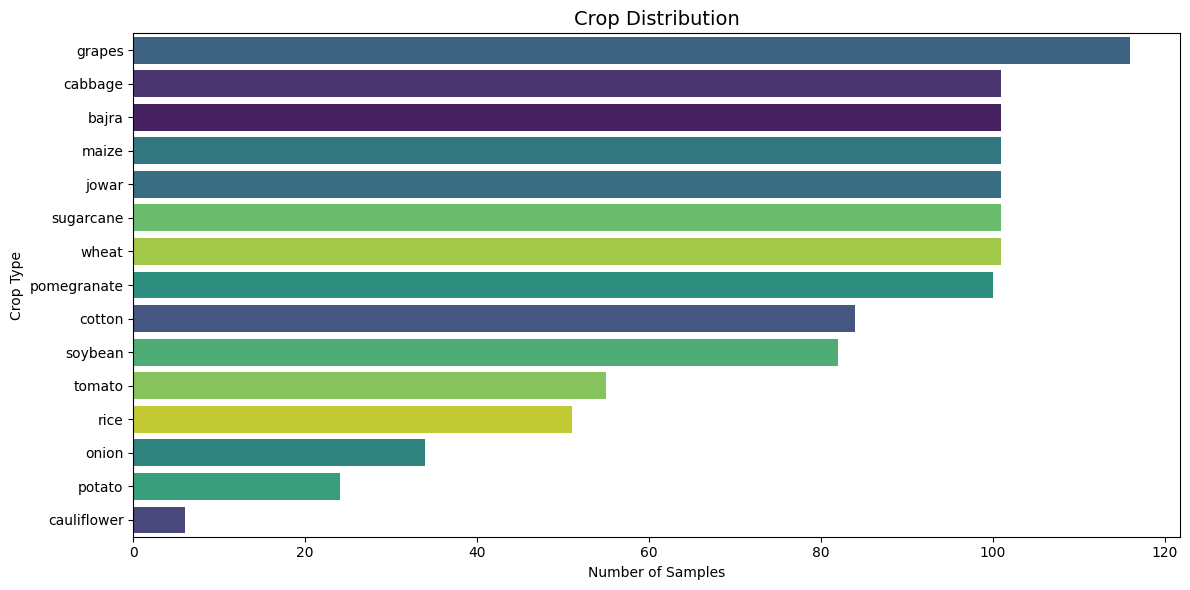

In [33]:
plt.figure(figsize=(12, 6))

sns.countplot(data=df, y='label', hue='label', 
              order=df['label'].value_counts().index, 
              palette='viridis', legend=False)

plt.title('Crop Distribution', fontsize=14)
plt.xlabel('Number of Samples')
plt.ylabel('Crop Type')
plt.tight_layout()
plt.show()

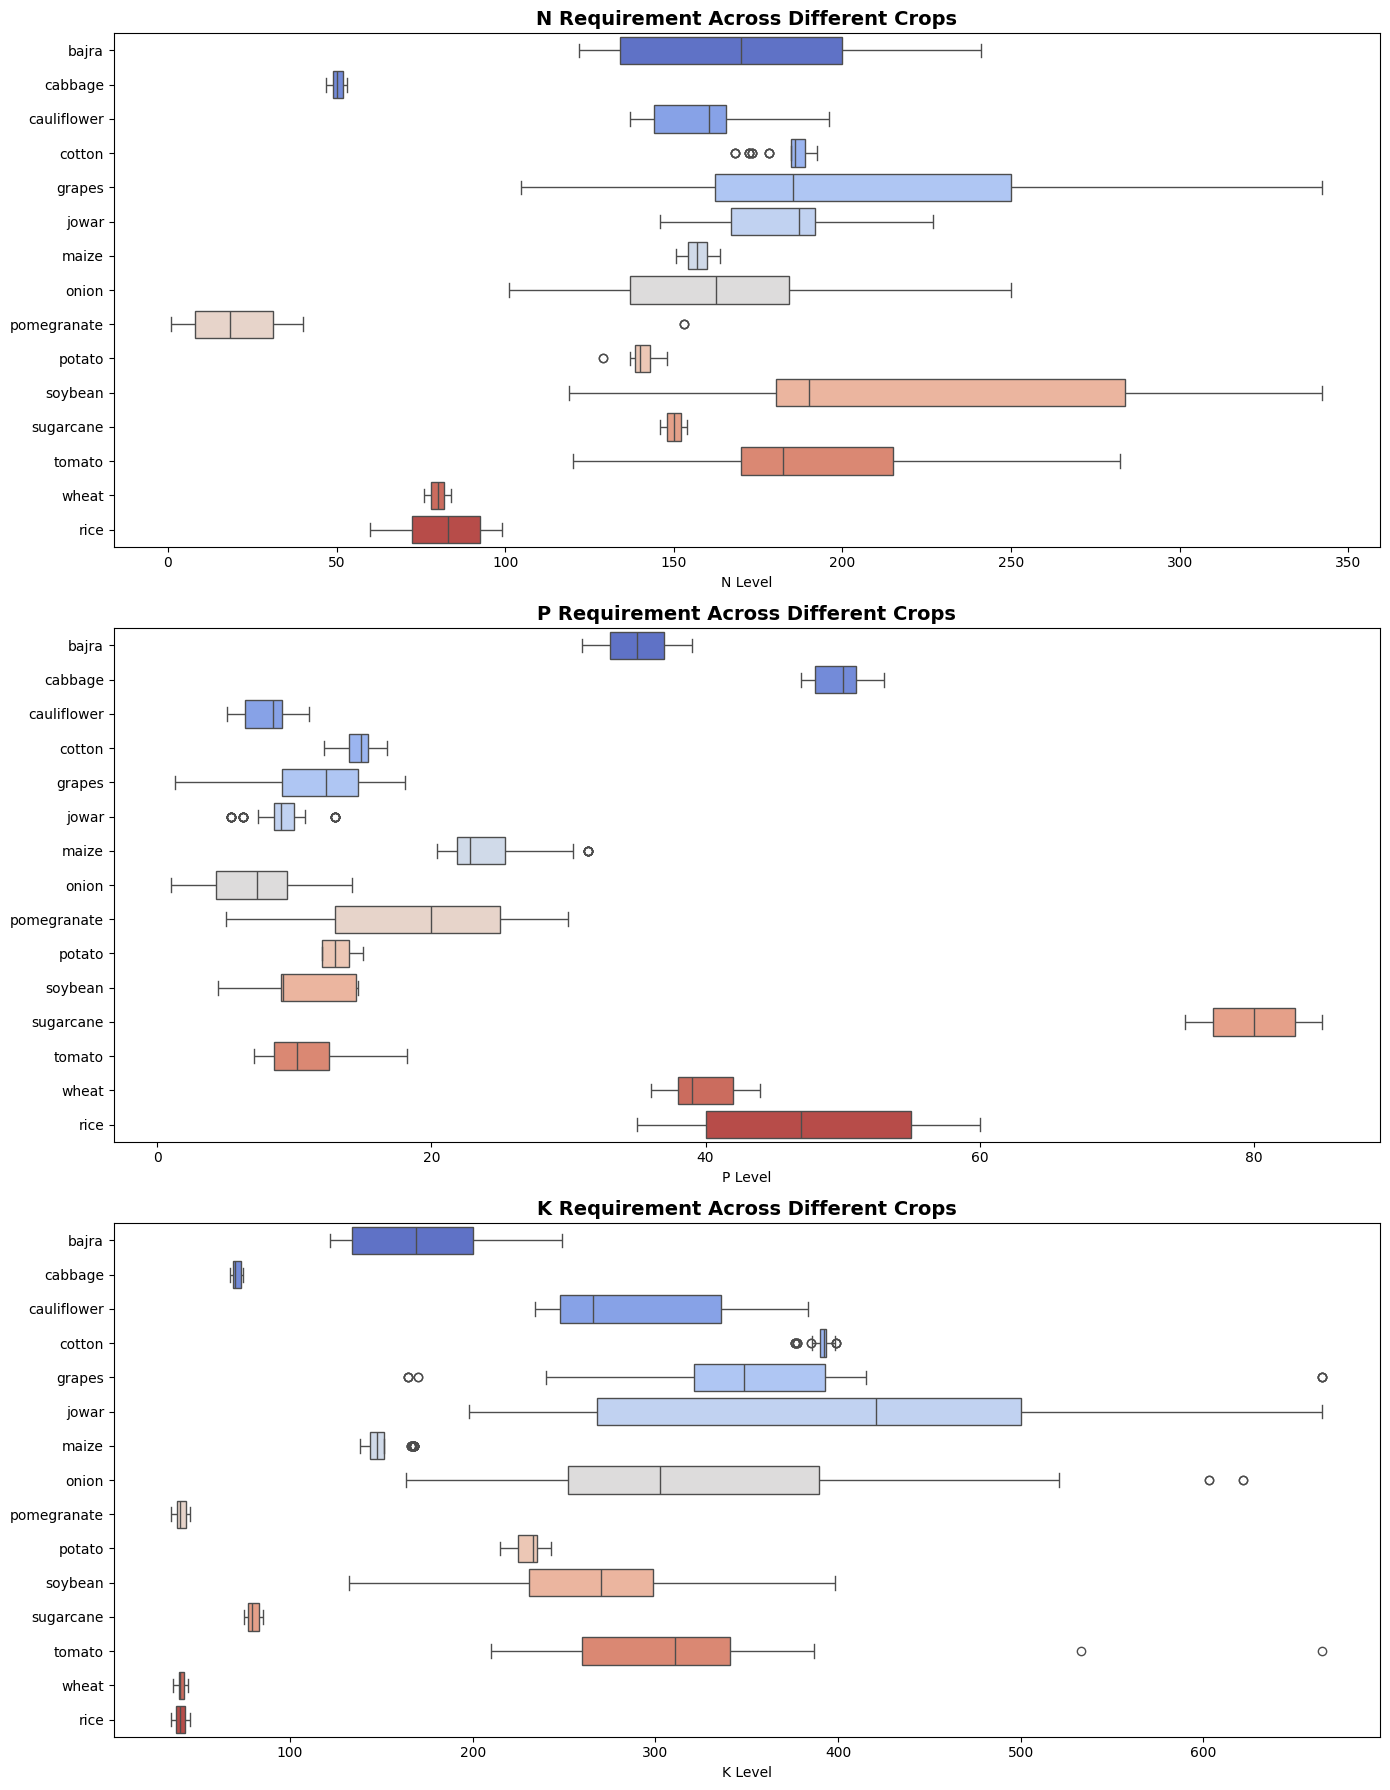

In [34]:
macro_nutrients = ['N', 'P', 'K']

fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(14, 18))

for i, col in enumerate(macro_nutrients):
    sns.boxplot(data=df, x=col, y='label', hue='label', 
                palette='coolwarm', legend=False, ax=axes[i])
    
    axes[i].set_title(f'{col} Requirement Across Different Crops', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('') 
    axes[i].set_xlabel(f'{col} Level')

plt.tight_layout()
plt.show()

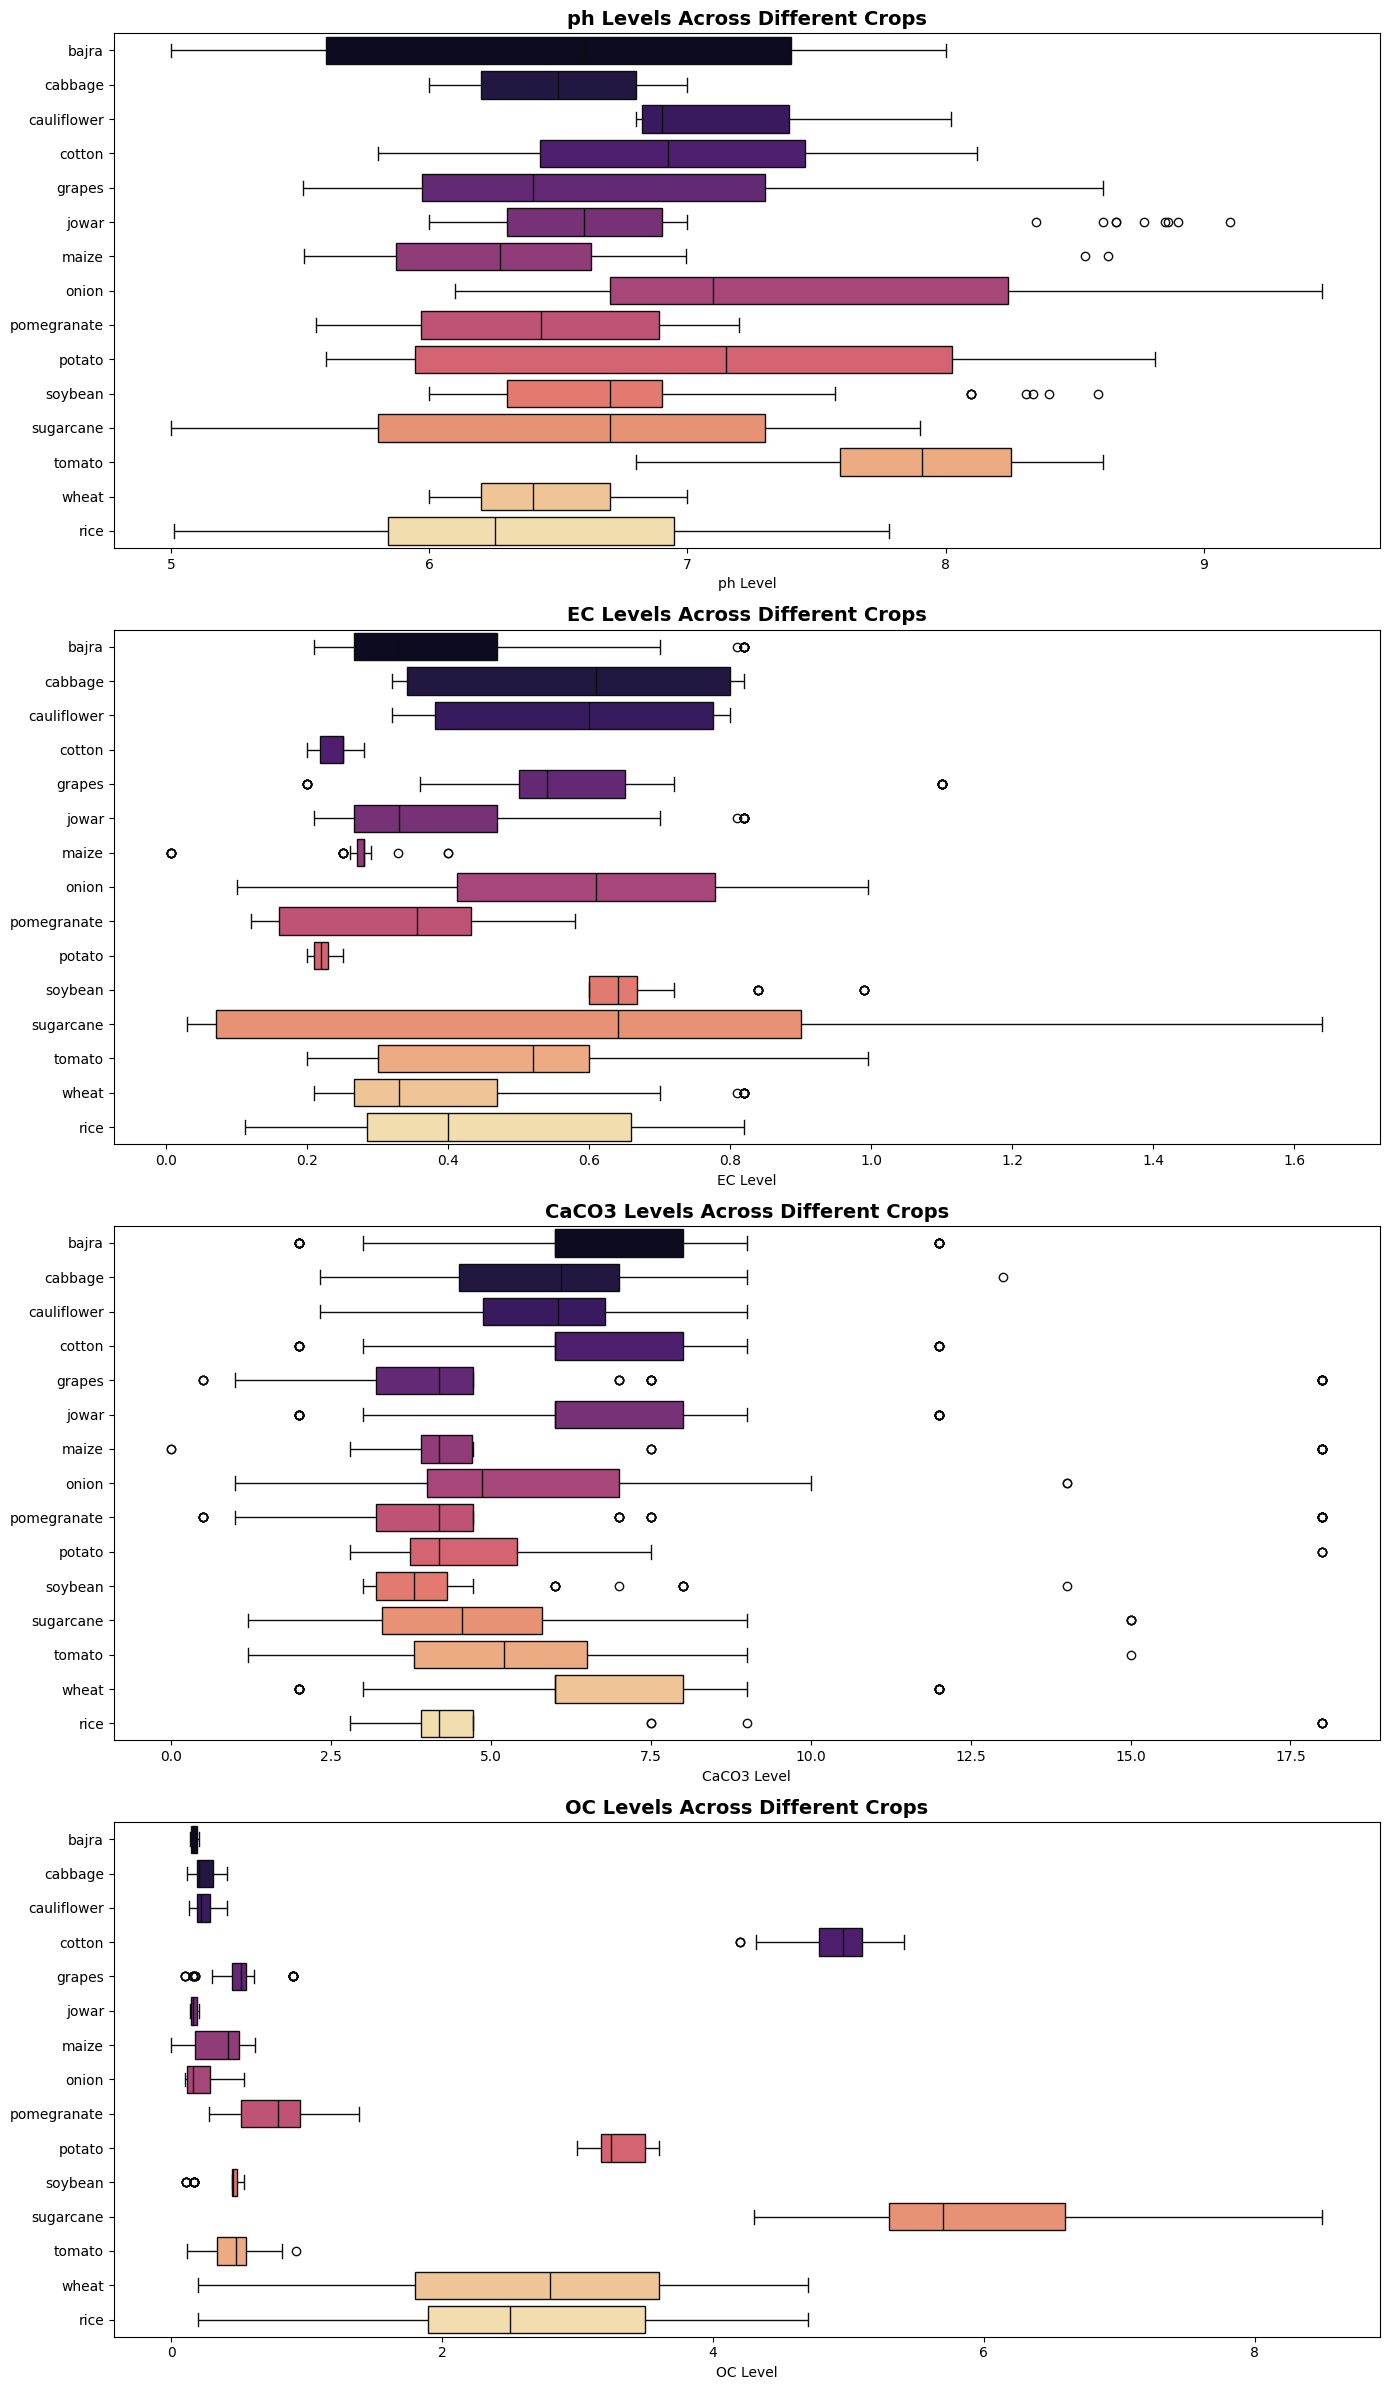

In [35]:
soil_props = ['ph', 'EC', 'CaCO3', 'OC']

fig, axes = plt.subplots(nrows=4, ncols=1, figsize=(14, 24))

for i, col in enumerate(soil_props):
    sns.boxplot(data=df, x=col, y='label', hue='label', 
                palette='magma', legend=False, ax=axes[i])
    
    axes[i].set_title(f'{col} Levels Across Different Crops', fontsize=14, fontweight='bold')
    axes[i].set_ylabel('') 
    axes[i].set_xlabel(f'{col} Level')

plt.tight_layout()
plt.show()

**Bivariate analysis (boxplots) ke zariye humne independent soil features (Macro Nutrients aur Physical Properties) ka target variable (Crop/label) ke sath direct relationship analyze kiya. Har crop ki nutrient requirement doosri se bilkul mukhtalif aur wazeh (distinct) nazar aayi. Zyadatar crops ke boxplots specific nutrients ke liye completely alag heights par the, jo zahir karta hai ke data mein classes aapas mein heavily overlap nahi kar rahin. Yeh clear "class separability" is baat ka strong statistical saboot hai ke hamare features mein high predictive power hai, jo aage chal kar Random Forest ya XGBoost jaise tree-based models ko mathematically accurate splits banane mein madad degi.**

# Multivariate Analysis

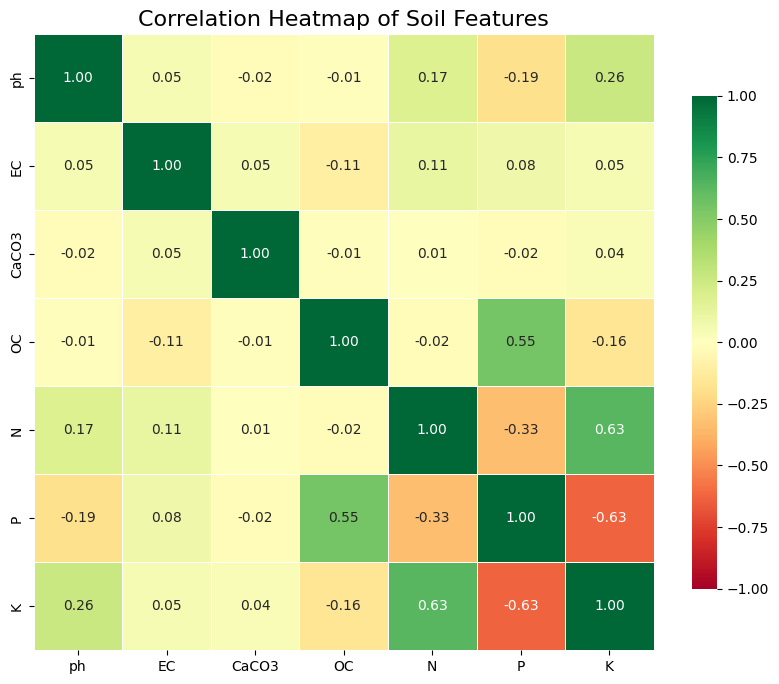

In [36]:
plt.figure(figsize=(10, 8))
corr_matrix = df[num_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='RdYlGn', 
            vmin=-1, vmax=1, center=0, fmt=".2f", linewidths=.5, cbar_kws={"shrink": .8})
plt.title('Correlation Heatmap of Soil Features', fontsize=16)
plt.show()

**Multivariate analysis mein correlation heatmap ne is dataset ki biological validity ko practically prove kar diya, kyunke isme features ke darmiyan natural chemical dependencies mojood hain. Heatmap se wazeh hua ke 'K' aur 'N' mein strong positive correlation (0.63) hai, jabke 'K' aur 'P' mein strong negative correlation (-0.62) observe ki gayi. Sab se ahem technical insight yeh mili ke dataset mein koi bhi do independent variables aapas mein highly correlated (e.g., > 0.85) nahi hain. Iska matlab hai ke data mein "Multicollinearity" ka masla mojood nahi, isliye humein Dimensionality Reduction (PCA) apply karne ya kisi makhsoos column ko drop karne ki zaroorat nahi hai.**

In [37]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data["Feature"] = num_cols
vif_data["VIF"] = [variance_inflation_factor(df[num_cols].values, i) for i in range(len(num_cols))]

print("Variance Inflation Factor (VIF):")
print(vif_data.sort_values(by="VIF", ascending=False).to_string(index=False))

Variance Inflation Factor (VIF):
Feature      VIF
      P 2.708795
      K 2.678708
      N 1.717316
     OC 1.664101
     EC 1.099741
     ph 1.084203
  CaCO3 1.006073


# Creating pipelines and using SMOTE

In [38]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

X = df.drop('label', axis=1)
y = df['label']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

dummy_pipeline = ImbPipeline(steps=[
    ('classifier', DummyClassifier(strategy='prior', random_state=42))
])

lr_pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('classifier', LogisticRegression(max_iter=2000, random_state=42, multi_class='multinomial'))
])

rf_pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=42))
])

xgb_pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=3)),
    ('classifier', XGBClassifier(n_estimators=100, random_state=42, eval_metric='mlogloss'))
])



**Train-Test split mein Cauliflower ke test set mein sirf 1 sample hone ki wajah se F1-score 0 aaraha tha (Due to extreme low support). Is anomaly ko handle karne aur model ki robust performance verify karne ke liye humne 5-Fold Stratified Cross-Validation implement ki.**

# Stratified K-fold cross

In [39]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Running 5-Fold Cross-Validation for Logistic Regression...")
lr_cv_scores = cross_val_score(lr_pipeline, X_train, y_train, cv=skf, scoring='f1_macro')

print("Running 5-Fold Cross-Validation for Random Forest...")
rf_cv_scores = cross_val_score(rf_pipeline, X_train, y_train, cv=skf, scoring='f1_macro')

print("Running 5-Fold Cross-Validation for XGBoost...")
xgb_cv_scores = cross_val_score(xgb_pipeline, X_train, y_train, cv=skf, scoring='f1_macro')

print(f"Logistic Regression CV Macro F1-Score: {lr_cv_scores.mean() * 100:.2f}% (+/- {lr_cv_scores.std() * 100:.2f}%)")
print(f"Random Forest CV Macro F1-Score: {rf_cv_scores.mean() * 100:.2f}% (+/- {rf_cv_scores.std() * 100:.2f}%)")
print(f"XGBoost CV Macro F1-Score:       {xgb_cv_scores.mean() * 100:.2f}% (+/- {xgb_cv_scores.std() * 100:.2f}%)")


Running 5-Fold Cross-Validation for Logistic Regression...
Running 5-Fold Cross-Validation for Random Forest...
Running 5-Fold Cross-Validation for XGBoost...
Logistic Regression CV Macro F1-Score: 72.08% (+/- 2.13%)
Random Forest CV Macro F1-Score: 87.82% (+/- 0.96%)
XGBoost CV Macro F1-Score:       87.24% (+/- 2.00%)


# Detailed Comparison of models

Final Model Comparison Table:


,Model,Macro F1-Score (%),Std Deviation (%)
0,Random Forest,87.818245,0.957234
1,XGBoost,87.240570,1.997714
2,Logistic Regression,72.084974,2.127606


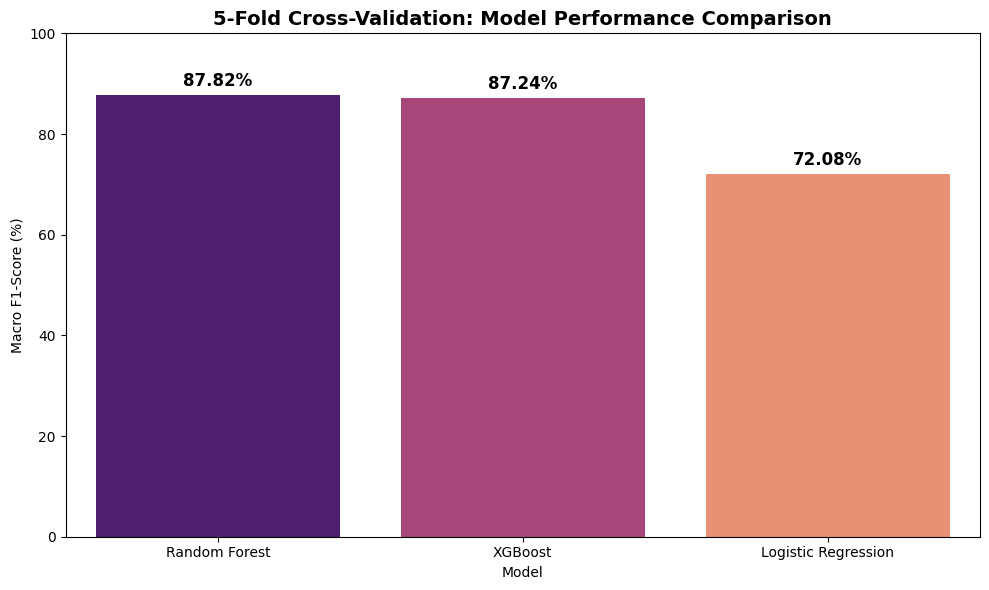

In [40]:
from IPython.display import display

model_comparison = pd.DataFrame({
    'Model': ['Random Forest', 'XGBoost', 'Logistic Regression'],
    'Macro F1-Score (%)': [rf_cv_scores.mean() * 100, xgb_cv_scores.mean() * 100, lr_cv_scores.mean() * 100],
    'Std Deviation (%)': [rf_cv_scores.std() * 100, xgb_cv_scores.std() * 100, lr_cv_scores.std() * 100]
})

model_comparison = model_comparison.sort_values(by='Macro F1-Score (%)', ascending=False).reset_index(drop=True)

print("Final Model Comparison Table:")
display(model_comparison)

plt.figure(figsize=(10, 6))
ax = sns.barplot(x='Model', y='Macro F1-Score (%)', data=model_comparison, palette='magma')
plt.title('5-Fold Cross-Validation: Model Performance Comparison', fontsize=14, fontweight='bold')
plt.ylim(0, 100)
plt.ylabel('Macro F1-Score (%)')

for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', 
                xytext=(0, 10), textcoords='offset points', 
                fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# XGB Selected

In [41]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report

print("Cross-Validated Predictions for XGBoost")
xgb_cv_preds = cross_val_predict(xgb_pipeline, X, y_encoded, cv=skf)

print("Detailed CV Classification Report (XGBoost):")
print(classification_report(y_encoded, xgb_cv_preds, target_names=le.classes_))

Cross-Validated Predictions for XGBoost
Detailed CV Classification Report (XGBoost):
              precision    recall  f1-score   support

       bajra       1.00      1.00      1.00       101
     cabbage       1.00      1.00      1.00       101
 cauliflower       0.00      0.00      0.00         6
      cotton       1.00      1.00      1.00        84
      grapes       0.93      0.91      0.92       116
       jowar       0.96      1.00      0.98       101
       maize       0.99      1.00      1.00       101
       onion       0.59      0.59      0.59        34
 pomegranate       0.99      0.97      0.98       100
      potato       1.00      1.00      1.00        24
        rice       0.98      0.90      0.94        51
     soybean       0.89      0.96      0.92        82
   sugarcane       1.00      1.00      1.00       101
      tomato       0.82      0.75      0.78        55
       wheat       0.96      1.00      0.98       101

    accuracy                           0.95      

# Limitation of this project

**During Cross-Validation, Cauliflower achieved a 0% F1-Score despite SMOTE. Upon deep analysis, it was observed that Cauliflower has extremely low support (only 6 samples) and its soil properties completely overlap with Cabbage (101 samples). Due to this lack of separability and extreme minority status, the model statistically classifies it as Cabbage. The professional recommendation for future work is either to collect more data for Cauliflower or drop this class to prevent noise.**

# Saving the model

In [42]:
import joblib

print("Training Final Model on 100% Data...")
final_model = xgb_pipeline.fit(X, y_encoded)

joblib.dump(final_model, 's2_npk_xgboost_pipeline.pkl')
joblib.dump(le, 'label_encoder.pkl')

print("Model and Encoders successfully saved as .pkl files!")

Training Final Model on 100% Data...
Model and Encoders successfully saved as .pkl files!


# Inferenece Function

In [47]:
import pandas as pd
import joblib

loaded_model = joblib.load('s2_npk_xgboost_pipeline.pkl')
loaded_le = joblib.load('label_encoder.pkl')

def recommend_crop_production(ph, ec, caco3, oc, n, p, k):
    if not (0 <= ph <= 14):
        return "Warning: pH value must be between 0 and 14."
    if n < 0 or p < 0 or k < 0:
        return "Warning: Nutrient values cannot be negative."
        
    input_data = pd.DataFrame({'ph': [ph], 'EC': [ec], 'CaCO3': [caco3], 'OC': [oc], 'N': [n], 'P': [p], 'K': [k]})
    
    probabilities = loaded_model.predict_proba(input_data)[0]
    top_3_indices = probabilities.argsort()[-3:][::-1]
    
    
    for i, idx in enumerate(top_3_indices):
        crop_name = loaded_le.inverse_transform([idx])[0].upper()
        prob_percentage = probabilities[idx] * 100
        print(f"{i+1}. {crop_name} (Confidence: {prob_percentage:.2f}%)")

recommend_crop_production(ph=6.5, ec=0.35, caco3=5.0, oc=0.5, n=120, p=40, k=150)

1. BAJRA (Confidence: 73.29%)
2. MAIZE (Confidence: 11.84%)
3. SUGARCANE (Confidence: 1.93%)


# Testing for data leakage

In [48]:
from sklearn.feature_selection import mutual_info_classif

print("--- STATISTICAL DATA LEAKAGE CHECK (MUTUAL INFORMATION) ---")
mi_scores = mutual_info_classif(X_train, y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

print("Mutual Information Scores (Higher means stronger dependency):")
print(mi_series)


--- STATISTICAL DATA LEAKAGE CHECK (MUTUAL INFORMATION) ---
Mutual Information Scores (Higher means stronger dependency):
N        2.046757
P        2.043396
K        1.979146
OC       1.790902
EC       1.626650
CaCO3    0.879928
ph       0.683580
dtype: float64


# Hyperparameter tuning of XGB

In [45]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np

param_grid = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 7, 9],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_grid,
    n_iter=15,               
    cv=skf,                  
    scoring='f1_macro',      
    random_state=42,
    n_jobs=-1,               
    verbose=2                
)

print("Running Randomized Search")
xgb_random_search.fit(X, y_encoded)

print(" HYPERPARAMETER TUNING RESULTS ")
print(f"Best CV Macro F1-Score: {xgb_random_search.best_score_ * 100:.2f}%")
print("\nBest Parameters Found:")

for param, value in xgb_random_search.best_params_.items():
    param_name = param.replace('classifier__', '')
    print(f" - {param_name}: {value}")

Running Randomized Search
Fitting 5 folds for each of 15 candidates, totalling 75 fits
 HYPERPARAMETER TUNING RESULTS 
Best CV Macro F1-Score: 89.53%

Best Parameters Found:
 - subsample: 0.9
 - n_estimators: 500
 - max_depth: 5
 - learning_rate: 0.2
 - colsample_bytree: 0.9
